# Encoding Geographical Risk from Global Sanctions Datasets

## A Structured Open Source Intelligence Tool to support Regulatory and AML/CFT Compliance
---

**Author**: Francesco Silvano, MEng in Engineering Management  

**Instructors**: Prof. Marco Maggini, Prof. Federico Becattini

**Course**: Business Intelligence, University of Siena 

**Publication Date**: June 2026

---

## Introduction & Context

Sanctions designation lists are maintained by dozens of jurisdictions — OFAC, the EU, the UN Security Council, and others — each with independent update cycles, entity formats, and coverage priorities. Cross-referencing these lists at scale is operationally expensive for compliance teams, and the absence of a unified analytical layer makes systematic pattern detection across regimes difficult for researchers and policy analysts alike.

This project builds a basic sanctions intelligence pipeline on top of [OpenSanctions](https://www.opensanctions.org/), a consolidated open-source repository of global sanctions and politically exposed persons (PEPs) data. The pipeline ingests and combines multiple datasets, enriches records through complementary data joins — adding sanctioned maritime vessels and financial securities — and validates data quality before analysis is run.

Three analytical techniques are applied: a **market-basket model** using the A-Priori algorithm to identify frequent co-occurrence patterns in entity attributes; a **recommendation system** based on UV decomposition via SGD to detect cross-list coverage gaps; and a **binary classifier** to assess whether a PEP profile is statistically consistent with sanctions designation. Findings are exposed through an interactive Quarto dashboard rendering this notebook.

The intended use cases are AML/CFT compliance screening, defense-sector entity monitoring, and geopolitical risk analysis.

---

### Methodology

The built pipeline ingests and combines multiple datasets, clean data and applies targeted preprocessing to ensure data is in a usable format and that any inconsistencies or missing values are addressed; an enrichment layer includes sanctioned maritime vessels and financial securities through complementary data joins - providing a holistic view of the activities carried out by sanctioned entities.

- In _Part I_ the datasets are explored to understand entity distributions, data quality, and country coverage across different sanction types;
- in _Part II_ three analytical layers are built: a **market-basket model** using the A-Priori algorithm identifies frequent co-occurrence patterns in entity attributes; **Jaccard Similarity** is applied to infer potential links between vessel records and sanctioned entities, and to rank non-sanctioned PEPs by profile similarity to designated ones; a **recommendation system** based on UV decomposition via SGD surfaces cross-list coverage gaps — flagging entities likely under-designated relative to their attribute profile;
- In _Part III_, a **simple binary classifier ML model** using Linear and Quadratic Discriminant Analysis is proposed to assesses whether a PEP profile is statistically consistent with sanctions designation, with a large-scale SGD classifier added as a higher-dimensional benchmark, attempting to predict risk levels based on geographical and entity-specific features, providing a probabilistic assessment of potential sanctions evasion.

#### A few assumptions on data quality to be aware of

- The analysis is based on the assumption that the datasets used are comprehensive and accurate representations of the entities and relationships involved in sanctions. While OpenSanctions is an authorative source, and their updates are frequent, the available data may not capture all information in real time, and there may be gaps or inaccuracies.

- Data is distributed in the **_FollowTheMoney (FTM)_** format, which is a specific structure for representing entities and their relationships. This format is in JSON, which requires significant preprocessing to be transformed into a structured format suitable for analysis. For the purpose of this project, a simpler version of the data in CSV format is used, which may not capture all the nuances and details present in the original JSON data. A pratical example: sanctions designation wouldn’t be in the PEPs collection because those sources don’t contain the designations texts. 

- The data originates from a variety of sources and therefore varies in terms of detail and precision (e.g., many listings of political office holders do not include their exact birth dates or full given names). This represents a significant challenge for data quality, as it can lead to difficulties in entity resolution and risk assessment. For instance, the lack of precise identifiers may result in false positives or negatives when screening for sanctioned entities, which can have serious implications for compliance efforts.

- The cut-off date for the data is set to 10/06/2026, and any events or changes that occurred after this date are not included in the analysis. This means that the findings may not reflect the most current state of sanctions and related activities.

---

### Technology Dependencies (TO REVIEW AT THE END)

```
0 Setup
└── 1 Ingest
    └── 2 Features
        ├── 3 Jaccard Dedup  ──────────────────────────────┐
        │   └── [deduped]                                  │
        │       ├── 4 Frequent Itemsets                    │
        │       │   └── [rules, fi_flags]                  │
        │       ├── 5 Network                              │
        │       │   └── [G, centrality, communities]       │
        │       │       ├── 6 Recommendation System        │
        │       │       │   └── [risk_score via UV]        │
        │       │       └── 7 ML Classifier ───────────────┘
        │       │           └── [risk_score]
        │       └── 8 Evasion Detection
        │           └── [evasion_score, evasion_flag]
        └── 9 Quarto Dashboard for Visualization
```

### Possible future applications
---

The intended use cases are compliance screening, defense-sector entity monitoring, and geopolitical risk analysis.

| # | Application | Description | Example |
| --- | --- | --- | --- |
| 1 | AML/CFT Counterparty Screening | Automated screening of counterparties, vendors, and transaction parties against the consolidated sanctions list. Fuzzy matching catches name variants and transliterations used to evade direct string matches — a common evasion technique. | A correspondent bank screens incoming wire transfers; the fuzzy matching layer flags "Rosneft Trading S.A." as a near-match to the designated "Rosneft Trading SA" on the EU FSF list, triggering an enhanced due diligence review before funds are released. |
| 2 | Sanctions Evasion Pattern Detection | Frequent itemset mining surfaces co-occurrence patterns in entity attributes — jurisdiction, schema type, cross-list membership — that characterise known evasion structures such as offshore shells, conduit flag states, and layered ownership chains. | The A-Priori algorithm identifies that entities sharing the profile {Company, country:AE, listed in OFAC} disproportionately lack an EU FSF designation. This cross-list coverage gap is consistent with UAE-incorporated intermediaries used to route sanctioned capital between Russian principals and European markets. |
| 3 | Geopolitical and Sectoral Risk Intelligence | Network centrality analysis maps which industries, jurisdictions, and corporate archetypes concentrate the most sanctioned connections — exposing emerging evasion corridors before they appear in formal designations. | A defense ministry analyst uses betweenness centrality scores to identify a cluster of Turkish shipping companies acting as structural brokers between sanctioned Russian oil producers and Asian buyers — a pattern not yet reflected in any active designation list. |
| 4 | Investigative Research and OSINT | An interactive dashboard for analysts, journalists, and NGOs to explore entity networks, trace ownership chains, and surface previously unknown connections between designated persons and ostensibly clean entities. The recommendation system surfaces candidate connections the user has not yet examined. | An investigative journalist queries the dashboard to trace the ownership chain of a vessel flagged under a conduit jurisdiction, linking it through three shell companies back to a sanctioned oligarch whose name does not appear in any public vessel registry. |

---

### Libraries and Imports

In [3]:
# Data
import pandas as pd
import numpy as np
from scipy import stats

# Other tools
import json, re, hashlib, itertools, collections, math, warnings
from pathlib import Path

# Similarity
from datasketch import MinHash, MinHashLSH        # MinHash-based Jaccard LSH

# A-Priori Algorithm
from mlxtend.frequent_patterns import apriori, association_rules 
from mlxtend.preprocessing import TransactionEncoder

# LDA, QDA use module: scikit learn
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.inspection import DecisionBoundaryDisplay

# Vizualization
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

# Machine Learning
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (classification_report, roc_auc_score, average_precision_score)
from sklearn.model_selection import StratifiedKFold
from scipy.sparse import lil_matrix, csr_matrix

DATA_PATH = "data/input"

### Collection and Update Process

The dataset coverage — i.e. when it was started and how frequently it is updated — is every six hours, and reflects the latest submissions and updates from the original sources. 

The dataset source is updated automatically; however, for the purposes of this project, a static snapshot of the data was taken on 10 June 2026, the date on which the final analysis was run, to ensure consistency across the analysis and avoid potential issues arising from changes to the data during the project timeline.

## Part I: Data Exploration and Preprocessing
---

### Cleaning the main datasets

The datasets required minimal pre-processing as they were sourced from a structured, actively maintained repository. Two issues were identified and addressed:

- Multi-value country fields storing semicolon-separated codes as a single string, which required splitting before any country-level analysis.
- Duplicate entries in the PEPs dataset across sources, resolved by retaining the most complete record per unique entity.

In particular, the PEPs dataset required a deduplication process due to duplicates present in different original data sources.

This process involved keeping the occurrence with the most complete information, i.e. the row with the fewest missing values across all columns. This approach ensured that the most informative record for each unique entity was retained while eliminating redundant entries that could have jeopardised the accuracy of our analysis.

### Describing the main datasets

#### DS1 Consolidated Sanctions

The _"Consolidated Sanctions"_ dataset is a distribution listing all the sanctioned entities designated by different countries and  international organisations. This can include military, trade and travel restrictions.

This collection combines all designated entities from the various sanctions lists included in OpenSanctions. It represents the broadest set of sanctioned people, companies and other assets that is designated globally.

In [4]:
# Load the data for Consolidated Sanctions dataset
df_consolidated = pd.read_csv(f"{DATA_PATH}/consolidatedsanctions/targets.simple-1.csv", low_memory=False).drop(columns=['phones','emails']) # phones and emails are dropped for simplicity
df_consolidated['countries'] = df_consolidated['countries'].str.upper()

Some records may have multiple `countries` separated by a semicolon. This means that specific entry has links to two countries. For example, a string like "RU;CY" could have different meanings such as _"Russian oligarch with Cypriot residency"_ or _"Russian company with a Cypriot branch"_.

In [5]:
df_consolidated['countries'].str.contains(';', na=False).sum()

np.int64(4575)

The number of those entities is **4575**. If left as-is, each entity would appear zero times in the RU count and zero times in the CY count. It almost certainly falls below a 2% threshold as a combined string, so it lands in the "Others" category, so this category would be artificially inflated. This represents a systematic bias against multi-jurisdiction entities. 

Therefore multi-country entities are disproportionately the analytically interesting ones - dual-national oligarchs, shell companies registered across multiple jurisdictions, intermediaries with deliberate geographic complexity.

#### DS2 Politically Exposed Persons (PEPs) dataset

The _"Politically Exposed Persons (PEPs)"_ dataset is a collection of individuals who are or have been entrusted with prominent public roles.

This dataset is important for financial institutions and other entities that are required to conduct enhanced due diligence on PEPs to mitigate risks of corruption and money laundering. It includes information on the individual's name, position, country of origin, and any associated risks.

In [6]:
# Load the data for the PEPs dataset
df_peps = pd.read_csv(f'{DATA_PATH}/peps/targets.simple-1.csv', low_memory=False) # low_memory=False to avoid dtype warnings
df_peps['countries'] = df_peps['countries'].str.upper()
df_peps

,id,schema,name,aliases,birth_date,countries,addresses,identifiers,sanctions,phones,emails,program_ids,dataset,first_seen,last_seen,last_change
0,NK-24KdLmG7SRFdS5GgJbgLSs,Person,"AW Kim Geok, PBS, PPA(P)",NaN,NaN,SG,NaN,NaN,NaN,NaN,aw_kim_geok@ite.edu.sg,NaN,Singapore Government Directory,2025-02-14T11:49:46,2026-05-06T00:07:19,2025-02-14T11:49:46
1,NK-24W9aosPLEsueQ5grGVNiK,Person,Christophane FOO,NaN,NaN,SG,NaN,NaN,NaN,NaN,Christophane_FOO@enterprisesg.gov.sg,NaN,Singapore Government Directory,2025-02-14T11:49:46,2026-05-06T00:07:19,2025-02-14T11:49:46
2,NK-24umfCYjCezXnS2gcCfT8F,Person,Andreas Norvik,NaN,1969-09-26,NO,NaN,NaN,NaN,NaN,NaN,NaN,Norway State-Owned Enterprises Leadership,2026-02-23T22:56:15,2026-04-22T14:39:39,2026-02-23T22:56:15
3,NK-25bxtBgjBTs6asnevNVgsE,Person,Sambhaji Rao Shinde,Shri Sambhaji Rao Shinde,NaN,IN,NaN,NaN,NaN,NaN,NaN,NaN,India Lok and Rajya Sabha Members,2025-10-13T12:10:55,2026-05-05T16:16:02,2025-10-13T12:10:55
4,NK-29DHCApxL2XswzxpKc6wva,Person,Rolf Skatteboe,NaN,1960-06-11,NO,NaN,NaN,NaN,NaN,NaN,NaN,Norway State-Owned Enterprises Leadership,2026-02-23T22:56:15,2026-04-22T14:39:39,2026-02-23T22:56:15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
741919,za-pmg-fc07125b875c410b7b81c9be51aa86b50a71e2c4,Person,Linda Xolelwa Hlobisile Hlongwa-Madlala,NaN,NaN,ZA,"Office 10, Dr Murugan Building, 5 Main Street ...",NaN,NaN,NaN,hlongwal@kznleg.gov.za,NaN,PEP position annotations by OpenSanctions;Sout...,2024-09-05T16:32:57,2026-05-07T13:37:03,2026-02-05T20:31:23
741920,za-pmg-fc1a0358099a1f66a7abac48528a39ca0416968a,Person,Fulufhelo Florence Radzilani,NaN,1970-09-14,ZA,Department of Health and Social Development Bu...,NaN,NaN,NaN,FrancisS@dsd.limpopo.gov.za;shivanifrancis26@g...,NaN,PEP position annotations by OpenSanctions;Sout...,2024-09-05T16:32:57,2026-05-07T13:37:03,2026-02-05T20:31:23
741921,za-pmg-fdd48f3a188d84f89e0074716820da3dafc87af1,Person,Anele Ernest Lizo,NaN,1983-12-17,ZA,NaN,NaN,NaN,NaN,NaN,NaN,PEP position annotations by OpenSanctions;Sout...,2024-09-05T16:32:57,2026-05-07T13:37:03,2026-02-05T20:31:23
741922,za-pmg-ff8ca6eb6f9638b63d158c5fa822ff092a406e7f,Person,Khethiwe Mildred Muthwa,NaN,NaN,ZA,NaN,NaN,NaN,NaN,NaN,NaN,South Africa National and Provincial Legislators,2024-09-05T16:32:57,2026-05-06T20:44:02,2026-02-05T20:31:23


In [7]:
df_peps.head()
n_peps = df_peps['id'].nunique()
n_duplicates = df_peps['name'].duplicated().sum()

print(f"Number of unique entities in PEPs dataset: {n_peps}")
print(f"Number of duplicates in PEPs dataset: {n_duplicates}")

df_duplicates = df_peps[df_peps['name'].duplicated(keep=False)].sort_values('name')
df_duplicates

Number of unique entities in PEPs dataset: 741924
Number of duplicates in PEPs dataset: 29095


,id,schema,name,aliases,birth_date,countries,addresses,identifiers,sanctions,phones,emails,program_ids,dataset,first_seen,last_seen,last_change
717606,sg-gov-a7992d9cdc07e49350b0880ad949143ec05da841,Person,A SELVERAJAH,NaN,NaN,SG,NaN,NaN,NaN,NaN,A_SELVERAJAH@mfa.gov.sg,NaN,Singapore Government Directory,2025-02-14T11:49:46,2026-05-06T00:07:19,2025-02-14T11:49:46
720098,sg-gov-c7f1e742c4a9b6f9a68d52835dbb52e465bf6614,Person,A SELVERAJAH,NaN,NaN,SG,NaN,NaN,NaN,NaN,A_SELVERAJAH@mfa.gov.sg,NaN,Singapore Government Directory,2025-02-14T11:49:46,2026-05-06T00:07:19,2025-02-14T11:49:46
161257,Q30524075,Person,A. Mani,NaN,NaN,IN,NaN,Q30524075,NaN,NaN,NaN,NaN,Wikidata Persons in Relevant Categories,2024-09-04T09:26:39,2026-05-06T03:53:24,2026-01-07T00:12:12
80738,Q133865340,Person,A. Mani,Mani A,1968-08-31,IN,"2/255A, Koodakaran Kottai Village A. Sappanipa...",Q133865340,NaN,NaN,NaN,NaN,India Lok and Rajya Sabha Members;PEP position...,2025-04-15T04:18:56,2026-05-07T13:37:03,2026-01-21T13:37:01
179699,Q4648173,Person,A. Marimuthu,NaN,NaN,IN,NaN,Q4648173,NaN,NaN,NaN,NaN,Wikidata Persons in Relevant Categories,2024-09-04T09:26:39,2026-05-06T03:53:24,2026-01-16T00:12:01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66092,Q130539861,Person,신동준,NaN,1932-12-10,KR,NaN,Q130539861,NaN,NaN,NaN,NaN,PEP position annotations by OpenSanctions;Wiki...,2025-05-05T12:48:14,2026-05-07T13:37:03,2026-01-15T03:48:43
66082,Q130539617,Person,이영애,NaN,1951-09-23,KR,NaN,Q130539617,NaN,NaN,NaN,NaN,PEP position annotations by OpenSanctions;Wiki...,2025-05-05T12:48:14,2026-05-07T13:37:03,2026-01-15T03:48:43
199403,Q55733317,Person,이영애,NaN,1948-09-21,KR,NaN,Q55733317,NaN,NaN,NaN,NaN,PEP position annotations by OpenSanctions;Wiki...,2025-03-31T13:59:24,2026-05-07T13:37:03,2026-01-16T00:12:01
59541,Q12619700,Person,최영희,NaN,1950-07-20,KR,NaN,Q12619700,NaN,NaN,NaN,NaN,PEP position annotations by OpenSanctions;Wiki...,2025-03-31T13:59:24,2026-05-07T13:37:03,2026-01-15T03:48:43


In [8]:
df_peps_work = df_peps.copy()
df_peps_work['non_null_count'] = df_peps_work.count(axis=1)

df_peps_work = df_peps_work.sort_values('non_null_count', ascending=False).drop_duplicates(subset='name', keep='first')

In [9]:
df_peps_work

,id,schema,name,aliases,birth_date,countries,addresses,identifiers,sanctions,phones,emails,program_ids,dataset,first_seen,last_seen,last_change,non_null_count
196776,Q54861079,Person,Mohamed-Iqbal Ravalia,"Ravalia, Mohamed-Iqbal",1957-08-15,CA;FR,Newfoundland and Labrador,Q54861079,NaN,+16139433676,Mohamed-iqbal.ravalia@sen.parl.gc.ca,NaN,Canada Members of the Senate;MySociety's Every...,2019-05-21T00:00:00,2026-05-07T13:37:03,2026-03-16T09:37:31,14
49049,Q121862,Person,Erich Hess,"Hess, Erich;Эрих Гесс;إريك هس",1981-03-25,CH,Berne;Dürrenroth,Q121862,NaN,+41313984200,erich.hess@parl.ch,NaN,MySociety's EveryPolitician Legislators;PEP po...,2019-05-21T00:00:00,2026-05-07T13:37:03,2026-03-16T10:26:30,14
131745,Q19853823,Person,Peter Shiu,SHIU Ka-fai;邵家輝;邵家辉,1970-04-22,CN;HK,"Room 1112, Legislative Council Complex, 1 Legi...",Q19853823,NaN,+85225373627;2537 3627,info@shiukafai.hk;kfshiu003@yahoo.com.hk,NaN,Hong Kong Legislative Council Members;MySociet...,2019-05-21T00:00:00,2026-05-07T13:37:03,2026-03-16T09:37:31,14
44908,Q11887897,Person,Pia Kauma,Kauma Pia;Pia Liisa Kauma,1966-10-20,FI,Espoo,Q11887897,NaN,+35894323069,pia.kauma@eduskunta.fi,NaN,Finland Members of Parliament;MySociety's Ever...,2019-05-21T00:00:00,2026-05-07T13:37:03,2026-03-16T09:37:31,14
44909,Q11887901,Person,Pia Viitanen,"Pia-Liisa Viitanen;Viitanen Pia;Вийтанен, Пиа",1967-04-07,FI,Tampere,Q11887901,NaN,+35894323039,pia.viitanen@eduskunta.fi,NaN,Finland Members of Parliament;MySociety's Ever...,2019-05-21T00:00:00,2026-05-07T13:37:03,2026-03-16T09:37:31,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
701575,ng-dots-precious-chikwendu-of-ng-dots-femi-fan...,Person,Precious Chikwendu,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Nigeria Joining the Dots PEPs and PEP Relatives,2023-10-23T10:04:48,2026-05-07T05:29:01,2023-10-23T10:04:48,7
701641,ng-dots-sa-ad-usman-of-ng-dots-nenadi-esther-u...,Person,Sa’Ad Usman,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Nigeria Joining the Dots PEPs and PEP Relatives,2023-10-23T10:04:48,2026-05-07T05:29:01,2023-10-23T10:04:48,7
702026,ng-dots-uzodinma-iweala-of-ng-dots-ngozi-okonj...,Person,Uzodinma Iweala,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Nigeria Joining the Dots PEPs and PEP Relatives,2023-10-23T10:04:48,2026-05-07T05:29:01,2023-10-23T10:04:48,7
702091,ng-dots-yuki-omenai-of-ng-dots-daisy-danjuma-1...,Person,Yuki Omenai,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Nigeria Joining the Dots PEPs and PEP Relatives,2023-10-23T10:04:48,2026-05-07T05:29:01,2023-10-23T10:04:48,7


In [10]:
df_sanctioned_people = df_consolidated[df_consolidated['schema'] == 'Person']
df_sanctioned_people

,id,schema,name,aliases,birth_date,countries,addresses,identifiers,sanctions,program_ids,dataset,first_seen,last_seen,last_change
6,NK-22HtK7WrxZ2sU3rmhz6PuZ,Person,Michael Kuajien,"KUAJIEN, Michael;Michael Kuajian;Michael Kuaji...",1979-01-01,KE;SS,Nairobi,NaN,GLOMAG - Executive Order 13818 (Global Magnitsky),US-GLOMAG,US OFAC Specially Designated Nationals (SDN) L...,2023-04-20T10:27:20,2026-05-08T06:54:29,2026-01-26T16:10:01
7,NK-22KNpaKJL84d8wpFudvLjN,Person,Чантурія Іраклі,CHANTURIA IRAKLI;CHANTURIA IRAKLII;Chanturiia ...,1983-05-29,GE;UA,NaN,NaN,203/2021 - updated - 2021-05-21;497/2021 - act...,UA-SA1644,Ukraine NSDC State Register of Sanctions,2023-04-20T10:50:14,2026-05-08T00:22:02,2026-01-06T08:22:01
11,NK-22c6upVtxbVMhbZb3Z6dn6,Person,Старовойтов Станіслав Юрійович,Starovoitov Stanislav;Starovoitov Stanislav Yu...,1982-10-11,RU,"Російська Федерація, Томська область, с. Бакчар",701722661674,726/2022 - active - 2022-10-19 - 2027-10-19,UA-SA1644,Ukraine NSDC State Register of Sanctions,2023-04-20T10:50:14,2026-05-08T00:22:02,2026-01-06T08:22:01
13,NK-22pPzcnpXeHiUgdXU3RcT8,Person,Дедюхін Олег Васильович,Dediukhin Oleg;Dediukhin Oleh Vasylovych;Дедюх...,1954-10-12,RU,NaN,165904188211,"295/2026 - дії іноземної держави, іноземної юр...",UA-SA1644,Ukraine NSDC State Register of Sanctions,2026-04-04T08:22:01,2026-05-08T00:22:02,2026-04-04T08:22:01
14,NK-22tXKtJr4xMCbfKZr5RzEz,Person,Khalid SBAA,NaN,1989-01-23,NaN,NaN,NRN 89.01.23-529.75,"""""",NaN,Belgian Financial Sanctions,2025-12-01T20:51:03,2026-05-08T06:17:09,2025-12-01T20:51:03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69610,us-klepto-hr-visa-venezuela-victor-jesus-lugo-...,Person,Victor Jesus Lugo Lugo,NaN,NaN,VE,NaN,NaN,Actions Taken Pursuant to Section 7031(c) for ...,NaN,US Anti-Kleptocracy and Human Rights Visa Rest...,2023-10-18T15:03:26,2026-05-08T03:27:01,2023-10-18T15:03:26
69611,us-klepto-hr-visa-venezuela-virginia-del-valle...,Person,Virginia Del Valle Lugo Lugo,NaN,NaN,VE,NaN,NaN,Actions Taken Pursuant to Section 7031(c) for ...,NaN,US Anti-Kleptocracy and Human Rights Visa Rest...,2023-10-18T15:03:26,2026-05-08T03:27:01,2023-10-18T15:03:26
69612,us-klepto-hr-visa-venezuela-yomaira-isabela-lu...,Person,Yomaira Isabela Lugo de Lugo,NaN,NaN,VE,NaN,NaN,Actions Taken Pursuant to Section 7031(c) for ...,NaN,US Anti-Kleptocracy and Human Rights Visa Rest...,2023-10-18T15:03:26,2026-05-08T03:27:01,2023-10-18T15:03:26
69613,us-klepto-hr-visa-vietnam-vo-thanh-dung,Person,Vo Thanh Dung,NaN,NaN,VN,NaN,NaN,Actions Taken Pursuant to Section 7031(c)(1) f...,NaN,US Anti-Kleptocracy and Human Rights Visa Rest...,2023-10-18T15:03:26,2026-05-08T03:27:01,2023-10-18T15:03:26


The `df_sanctioned_people` dataframe contains only the entities from the Consolidated Sanctions dataset that are classified as 'Person' under the 'schema' column. These are all the individuals that have been designated as sanctioned entities by different countries and international organisations.

#### Distribution of sanctioned individuals by country

##### Sanctioned individuals that are not PEPs

In [11]:
df_sanctioned_people_nopeps = df_sanctioned_people[~df_sanctioned_people['id'].isin(df_peps_work['id'])]
df_sanctioned_people_nopeps

,id,schema,name,aliases,birth_date,countries,addresses,identifiers,sanctions,program_ids,dataset,first_seen,last_seen,last_change
6,NK-22HtK7WrxZ2sU3rmhz6PuZ,Person,Michael Kuajien,"KUAJIEN, Michael;Michael Kuajian;Michael Kuaji...",1979-01-01,KE;SS,Nairobi,NaN,GLOMAG - Executive Order 13818 (Global Magnitsky),US-GLOMAG,US OFAC Specially Designated Nationals (SDN) L...,2023-04-20T10:27:20,2026-05-08T06:54:29,2026-01-26T16:10:01
7,NK-22KNpaKJL84d8wpFudvLjN,Person,Чантурія Іраклі,CHANTURIA IRAKLI;CHANTURIA IRAKLII;Chanturiia ...,1983-05-29,GE;UA,NaN,NaN,203/2021 - updated - 2021-05-21;497/2021 - act...,UA-SA1644,Ukraine NSDC State Register of Sanctions,2023-04-20T10:50:14,2026-05-08T00:22:02,2026-01-06T08:22:01
11,NK-22c6upVtxbVMhbZb3Z6dn6,Person,Старовойтов Станіслав Юрійович,Starovoitov Stanislav;Starovoitov Stanislav Yu...,1982-10-11,RU,"Російська Федерація, Томська область, с. Бакчар",701722661674,726/2022 - active - 2022-10-19 - 2027-10-19,UA-SA1644,Ukraine NSDC State Register of Sanctions,2023-04-20T10:50:14,2026-05-08T00:22:02,2026-01-06T08:22:01
13,NK-22pPzcnpXeHiUgdXU3RcT8,Person,Дедюхін Олег Васильович,Dediukhin Oleg;Dediukhin Oleh Vasylovych;Дедюх...,1954-10-12,RU,NaN,165904188211,"295/2026 - дії іноземної держави, іноземної юр...",UA-SA1644,Ukraine NSDC State Register of Sanctions,2026-04-04T08:22:01,2026-05-08T00:22:02,2026-04-04T08:22:01
14,NK-22tXKtJr4xMCbfKZr5RzEz,Person,Khalid SBAA,NaN,1989-01-23,NaN,NaN,NRN 89.01.23-529.75,"""""",NaN,Belgian Financial Sanctions,2025-12-01T20:51:03,2026-05-08T06:17:09,2025-12-01T20:51:03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69610,us-klepto-hr-visa-venezuela-victor-jesus-lugo-...,Person,Victor Jesus Lugo Lugo,NaN,NaN,VE,NaN,NaN,Actions Taken Pursuant to Section 7031(c) for ...,NaN,US Anti-Kleptocracy and Human Rights Visa Rest...,2023-10-18T15:03:26,2026-05-08T03:27:01,2023-10-18T15:03:26
69611,us-klepto-hr-visa-venezuela-virginia-del-valle...,Person,Virginia Del Valle Lugo Lugo,NaN,NaN,VE,NaN,NaN,Actions Taken Pursuant to Section 7031(c) for ...,NaN,US Anti-Kleptocracy and Human Rights Visa Rest...,2023-10-18T15:03:26,2026-05-08T03:27:01,2023-10-18T15:03:26
69612,us-klepto-hr-visa-venezuela-yomaira-isabela-lu...,Person,Yomaira Isabela Lugo de Lugo,NaN,NaN,VE,NaN,NaN,Actions Taken Pursuant to Section 7031(c) for ...,NaN,US Anti-Kleptocracy and Human Rights Visa Rest...,2023-10-18T15:03:26,2026-05-08T03:27:01,2023-10-18T15:03:26
69613,us-klepto-hr-visa-vietnam-vo-thanh-dung,Person,Vo Thanh Dung,NaN,NaN,VN,NaN,NaN,Actions Taken Pursuant to Section 7031(c)(1) f...,NaN,US Anti-Kleptocracy and Human Rights Visa Rest...,2023-10-18T15:03:26,2026-05-08T03:27:01,2023-10-18T15:03:26


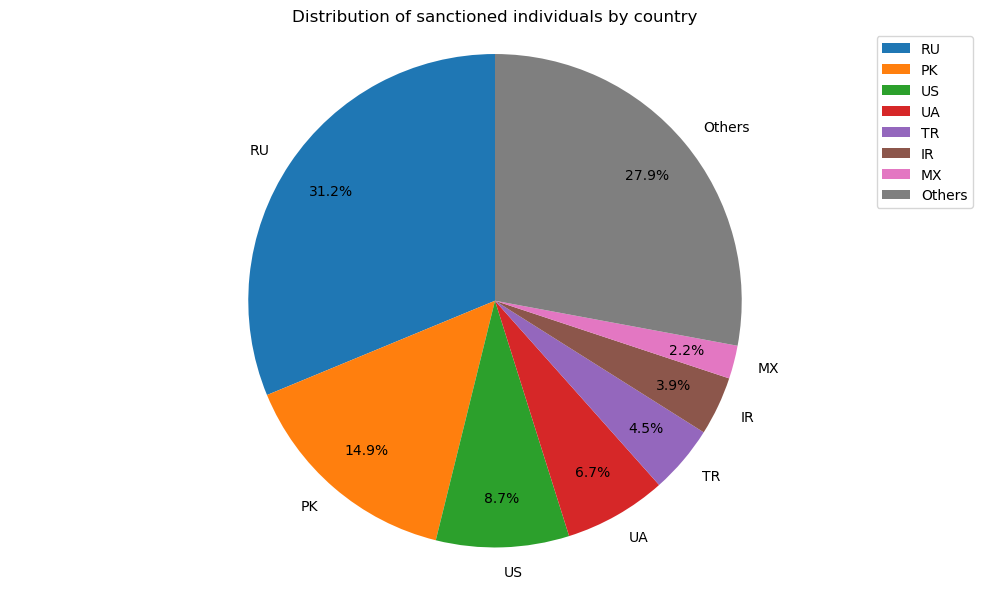

In [12]:
country_counts_nopeps = df_sanctioned_people_nopeps['countries'].str.split(';').explode().str.strip().value_counts()

country_percentage_nopeps = country_counts_nopeps / country_counts_nopeps.sum()

main_countries_nopeps = country_counts_nopeps[country_percentage_nopeps >= 0.02]
other_countries_nopeps = country_counts_nopeps[country_percentage_nopeps < 0.02].sum()

plot_data = main_countries_nopeps.copy()
if other_countries_nopeps > 0:
    plot_data['Others'] = other_countries_nopeps

fig = plt.figure(figsize=(10, 6))
plot_data.plot(
    kind='pie',
    autopct='%1.1f%%', # autopct to show percentage on the pie chart
    startangle=90,
    pctdistance=0.8
)

plt.title('Distribution of sanctioned individuals by country')
plt.axis('equal')
plt.tight_layout()
plt.legend()
plt.show()

##### Sanctioned individuals that are also PEPs

Analyzing the distribution of the sanctioned PEPs by country allows us to understand how many politically exposed persons are sanctioned in each country, and to identify any patterns or trends in the distribution of sanctions across different countries. This can provide insights into the geopolitical and economic factors that may influence sanctions designation, and can inform risk assessment and compliance efforts for entities operating in those countries.

In [13]:
df_sanctioned_people_peps = pd.merge(df_sanctioned_people, df_peps_work, on='id', how='inner', suffixes=('_consolidated', '_peps'))
df_sanctioned_people_peps

,id,schema_consolidated,name_consolidated,aliases_consolidated,birth_date_consolidated,countries_consolidated,addresses_consolidated,identifiers_consolidated,sanctions_consolidated,program_ids_consolidated,...,identifiers_peps,sanctions_peps,phones,emails,program_ids_peps,dataset_peps,first_seen_peps,last_seen_peps,last_change_peps,non_null_count
0,NK-BSEuishRCnUhGGStYWEtGt,Person,Hermann Eduardo ESCARRA MALAVE,"ESCARRA MALAVE, Hermann Eduardo;Hermann Eduard...",1952-04-08,VE,"Miranda, Miranda",3820195,VENEZUELA - Executive Order 13692 (Venezuela);...,CA-SEMA;US-VEN,...,NaN,NaN,NaN,NaN,NaN,PEP position annotations by OpenSanctions;Vene...,2024-01-30T20:02:45,2026-05-07T13:37:03,2026-04-15T21:33:50,8
1,NK-BcU6kPxJiL4AeJn6f4ujwS,Person,America Valentina Perez Davila,"PEREZ DAVILA, America Valentina",1993-11-27,VE,NaN,V20901866,VENEZUELA - Executive Order 13692 (Venezuela),US-VEN,...,NaN,NaN,NaN,NaN,NaN,PEP position annotations by OpenSanctions;Vene...,2024-01-30T20:02:45,2026-05-07T13:37:03,2026-04-15T21:33:50,8
2,NK-QeQteG9tqe895L4aaBfT85,Person,Emrush XHEMAJLI,"XHEMAJLI, Emrush",1959-05-05,NaN,NaN,NaN,BALKANS - Unknown,US-BALKANS,...,NaN,NaN,NaN,NaN,NaN,MySociety's EveryPolitician Legislators;PEP po...,2019-05-21T00:00:00,2026-05-07T13:37:03,2026-03-16T09:37:31,10
3,NK-SifJyUiXJfmymXcP5F89M7,Person,Ramiz LLADROVICI,"LLADROVICI, Ramiz",1966-01-03,NaN,NaN,NaN,BALKANS - Unknown,US-BALKANS,...,NaN,NaN,NaN,NaN,NaN,MySociety's EveryPolitician Legislators;PEP po...,2019-05-21T00:00:00,2026-05-07T13:37:03,2026-03-16T09:37:31,10
4,NK-TAZ2PvEBNvLMqgCBsz9BTe,Person,Andres Laureano Gonzalez Brito,"Andrés Laureano González Brito;GONZALEZ BRITO,...",1954-07-04,CU,Havana,NaN,GLOMAG - Executive Order 13818 (Global Magnitsky),US-GLOMAG,...,NaN,NaN,NaN,NaN,NaN,Cuba Members of the Parliament;PEP position an...,2023-08-14T15:43:35,2026-05-07T13:37:03,2026-03-16T09:36:35,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3338,Q99767942,Person,Alena PANTSIUKHOVA,NaN,1972-12-20,NaN,NaN,NaN,2023-05-30,NaN,...,Q99767942,NaN,NaN,NaN,NaN,Wikidata Persons in Relevant Categories;Wikida...,2023-04-20T10:30:17,2026-05-06T03:53:24,2026-01-15T03:48:43,10
3339,Q99769144,Person,Aliaksandr LIAKHAU,NaN,1962-07-07,NaN,NaN,NaN,2023-05-31,NaN,...,Q99769144,NaN,NaN,NaN,NaN,Wikidata Persons in Relevant Categories;Wikida...,2023-04-20T10:30:17,2026-05-06T03:53:24,2026-01-15T03:48:43,10
3340,Q99837867,Person,Aliaksandr SHYSHKO,NaN,1959-09-24,NaN,NaN,NaN,2023-05-30,NaN,...,Q99837867,NaN,NaN,NaN,NaN,Wikidata Persons in Relevant Categories;Wikida...,2023-04-20T10:30:17,2026-05-06T03:53:24,2026-01-15T03:48:43,10
3341,Q99861219,Person,Ivan Ivanavich GALAVATYI,Galavatyi Ivan Ivanavich;Golovaty Ivan Ivanovi...,1976-06-15,BY,NaN,NaN,(UE) 2025/386 du 24/02/2025 (UE Biélorussie - ...,CA-SEMA;EU-BLR;SECO-BRUS,...,Q99861219,NaN,NaN,NaN,NaN,Wikidata Persons in Relevant Categories;Wikida...,2023-04-20T10:30:17,2026-05-06T03:53:24,2026-01-18T00:12:11,10


The resulting dataset is typically named "The Russian Government" by the OpenSanctions team for the presence of many high-profile Russian politicians and oligarchs who are both sanctioned and politically exposed. This subset can potentially be analyzed further to understand the overlap between the two datasets and to identify any unique characteristics of these entities, but it's out of project scope.

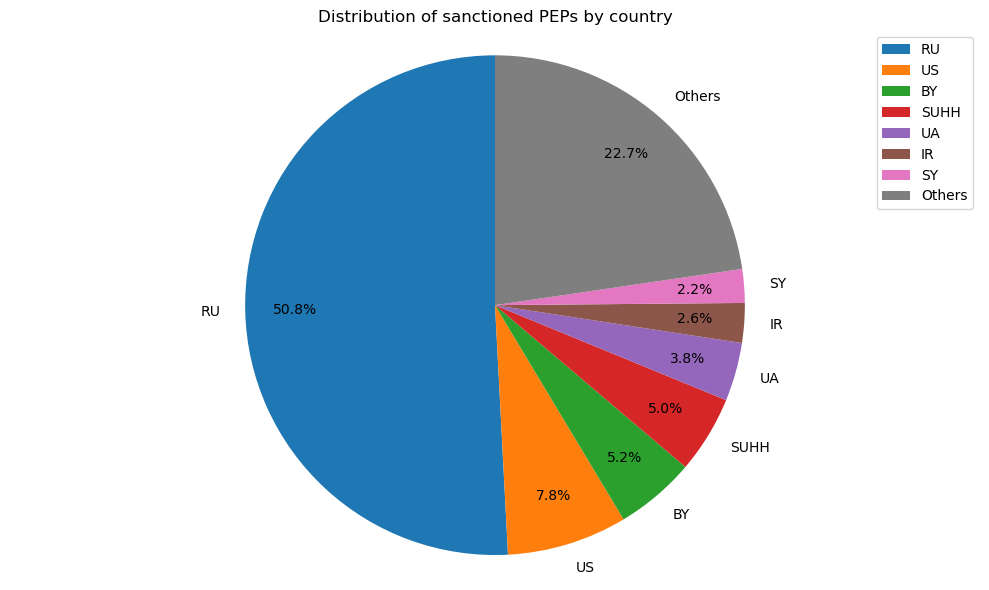

In [14]:
country_counts_peps = df_sanctioned_people_peps['countries_peps'].str.split(';').explode().str.strip().value_counts()

country_percentage_peps = country_counts_peps / country_counts_peps.sum()

main_countries_peps = country_counts_peps[country_percentage_peps >= 0.02]
other_countries_peps = country_counts_peps[country_percentage_peps < 0.02].sum()

plot_data = main_countries_peps.copy()
if other_countries_peps > 0:
    plot_data['Others'] = other_countries_peps

fig = plt.figure(figsize=(10, 6))
plot_data.plot(
    kind='pie',
    autopct='%1.1f%%', # autopct to show percentage on the pie chart
    startangle=90,
    pctdistance=0.8
)

plt.title('Distribution of sanctioned PEPs by country')
plt.axis('equal')
plt.tight_layout()
plt.legend()
plt.show()

### Describing the Enrichment Layers

#### Distribution of sanctioned non-individual entities by country

In this section, we introduce two layers of enrichment. The first layer identifies _**Maritime Vessels**_ subject to sanctions and attempts to uncover hidden links to sanctioned entities. Vessels can be used to circumvent trade sanctions and are not always directly linked to sanctioned entities; they are sometimes linked to shell companies that mask the main entity, which may be an organisation, a company or, though this is rare, a high-profile individual. The second layer concerns sanctioned securities. By _**"Sanctioned Security"**_, we mean a tradable (though not necessarily traded) financial asset that holds monetary value. The specialised "Sanctioned Securities" dataset maps sanctioned companies to their tradable financial assets.

##### EL1 Sanctioned vessels

In [15]:
df_maritime = pd.read_csv(f'{DATA_PATH}/maritime/maritime.csv', low_memory=False) # low_memory=False to avoid dtype warnings
df_maritime['countries'] = df_maritime['countries'].str.upper()
df_maritime['flag'] = df_maritime['flag'].str.upper()

In [16]:
df_maritime

,type,caption,imo,risk,countries,flag,mmsi,id,url,datasets,aliases
0,VESSEL,BOUDREAUX TIDE,IMO9427366,mare.detained;reg.warn,VU,VU,NaN,abuja-mou-det-0059aae88f59011c58de8f5bc1d7d986...,https://www.opensanctions.org/entities/abuja-m...,abuja_mou_detention,NaN
1,VESSEL,MT UNGIESHI,IMO9261841,mare.detained;reg.warn,PA,PA,NaN,abuja-mou-det-008a22106d7ad7f4d4e184b01bbd61f4...,https://www.opensanctions.org/entities/abuja-m...,abuja_mou_detention,NaN
2,VESSEL,HACI SEMSETTIN DUNDAR,IMO9045699,mare.detained;reg.warn,PA,PA,NaN,abuja-mou-det-088511901b0456a70ec6288207972686...,https://www.opensanctions.org/entities/abuja-m...,abuja_mou_detention,NaN
3,VESSEL,SIRAYA WISDOM,IMO9403841,mare.detained,PA,PA,NaN,abuja-mou-det-094320324411c3158780fc172d24b2cb...,https://www.opensanctions.org/entities/abuja-m...,abuja_mou_detention,NaN
4,VESSEL,BBC OLYMPUS,IMO9508457,mare.detained,AG,AG,NaN,abuja-mou-det-0a5094c74d3f88de2254405dfe3d8aa1...,https://www.opensanctions.org/entities/abuja-m...,abuja_mou_detention,NaN
...,...,...,...,...,...,...,...,...,...,...,...
17314,VESSEL,DONG FENG 6,IMO9008201,sanction,NaN,NaN,NaN,un-1718-f63806bb0ad4c75d3347907c5684a669fc4f636e,https://www.opensanctions.org/entities/un-1718...,un_1718_vessels,NaN
17315,VESSEL,Hangton No. 112,NaN,sanction,NaN,NaN,NaN,us-cbpfl-0b3f7392a785c689f86ea31cc4b21cef1eb2c00b,https://www.opensanctions.org/entities/us-cbpf...,us_cbp_forced_labor,NaN
17316,VESSEL,Lien Yi Hsing No. 12,NaN,sanction,NaN,NaN,NaN,us-cbpfl-6dd36877071adfe36f7652f93f5ba3bef70fa1ea,https://www.opensanctions.org/entities/us-cbpf...,us_cbp_forced_labor,NaN
17317,VESSEL,Zhen Fa 7,NaN,sanction,CN,NaN,NaN,us-cbpfl-b64c9884986c6a2bb6d5d1683e8700fd66645346,https://www.opensanctions.org/entities/us-cbpf...,us_cbp_forced_labor,NaN


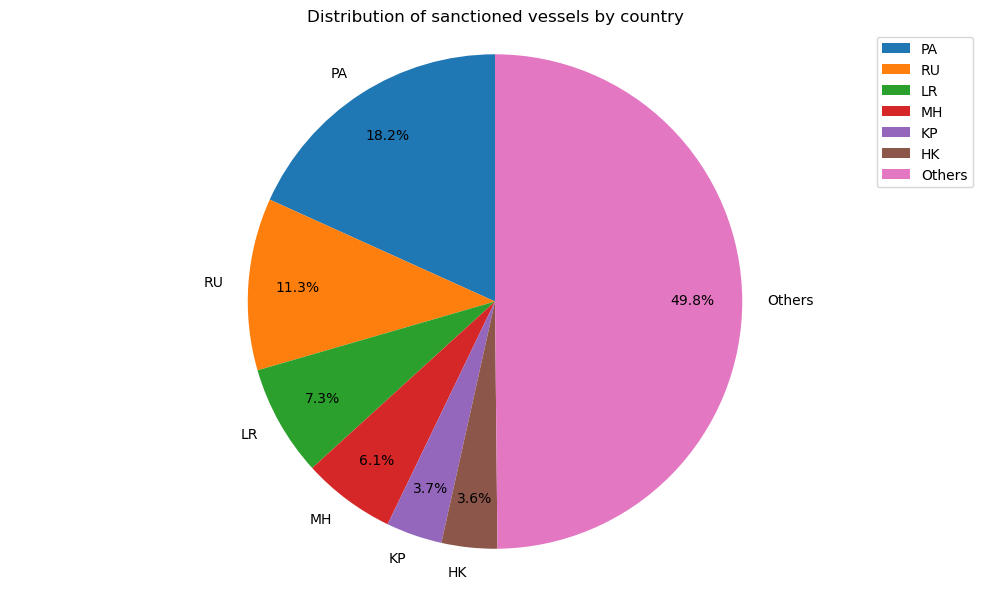

In [17]:
country_counts = df_maritime['countries'].value_counts()

country_percentage = country_counts / country_counts.sum()

main_countries = country_counts[country_percentage >= 0.02]
other_countries = country_counts[country_percentage < 0.02].sum()

plot_data = main_countries.copy()
if other_countries > 0:
    plot_data['Others'] = other_countries

fig = plt.figure(figsize=(10, 6))
plot_data.plot(
    kind='pie',
    autopct='%1.1f%%', # autopct to show percentage on the pie chart
    startangle=90,
    pctdistance=0.8
)

plt.title('Distribution of sanctioned vessels by country')
plt.axis('equal')
plt.tight_layout()
plt.legend()
plt.show()

##### EL2 Sanctioned securities

In [18]:
df_securities = pd.read_csv(f'{DATA_PATH}/securities/securities.csv', low_memory=False)
df_securities['countries'] = df_securities['countries'].str.upper()

In [19]:
df_securities

,caption,lei,perm_id,isins,ric,countries,sanctioned,eo_14071,public,id,url,datasets,risk_datasets,aliases,referents
0,"Myanmar Yatai International Holding Group Co.,...",NaN,NaN,NaN,NaN,MM,t,f,f,NK-223CQDBzp8MRkdJMDiqXn3,https://www.opensanctions.org/entities/NK-223C...,us_ofac_sdn,us_ofac_sdn,"Myanmar Yatai International Holding Group Co.,...",oc-companies-mm-1fc-2016-2017-kyn;ofac-54742;o...
1,OJSC EHMZ named after N. D. Zelinsky,NaN,NaN,NaN,NaN,RU,t,f,f,NK-226GXBdQ5p6NjgrTpTQNVW,https://www.opensanctions.org/entities/NK-226G...,ch_seco_sanctions;eu_fsf;eu_journal_sanctions,ch_seco_sanctions;eu_fsf;eu_journal_sanctions,Fábrica de produtos químicos e mecânicos que r...,be-fod-e74ddc4806de2878afe5caf44883341bc23dad3...
2,Limited Liability Company Specialized Develope...,NaN,NaN,NaN,NaN,RU,t,f,f,NK-22MHXvQQufBgTjUWgUbWb8,https://www.opensanctions.org/entities/NK-22MH...,us_ofac_sdn,us_ofac_sdn,LLC Specialized Developer Alabuga South Park;L...,ofac-47297;ofac-pr-8b6d0f8d6541274066986792288...
3,Digital Marketing Awards FZ LLC,NaN,5090601059,NaN,NaN,AE,t,f,f,NK-22T6dTsc6umYgEA33vME3t,https://www.opensanctions.org/entities/NK-22T6...,permid;us_ofac_sdn,us_ofac_sdn,Digital Marketing Awards FZ LLC;Digital Market...,ofac-49834;ofac-pr-14fa36d7ba9e9f60363ab2b7bab...
4,EKVIK LIMITED LIABILITY COMPANY,NaN,NaN,NaN,NaN,RU,t,f,f,NK-22cQD3a8GDRSuoW5mus3F3,https://www.opensanctions.org/entities/NK-22cQ...,us_ofac_sdn,us_ofac_sdn,EKVIK LIMITED LIABILITY COMPANY,ofac-51081;ofac-pr-c7983e4cf948daa5d07f11f8cfd...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11888,Jiangyin Lianyun Co. Ltd.,NaN,NaN,NaN,NaN,CN,t,f,f,us-uflpa-e038fe2617a53578a9a891aa32dab5fd1baa7608,https://www.opensanctions.org/entities/us-uflp...,us_dhs_uflpa,us_dhs_uflpa,Jiangyin Intermodal Transport Co. and Jiangyin...,NaN
11889,Jiangsu Yinhai Nongjiale Storage Co. Ltd.,NaN,NaN,NaN,NaN,CN,t,f,f,us-uflpa-e650617987b2f3ac5deb8d0fcf04e18b89dde537,https://www.opensanctions.org/entities/us-uflp...,us_dhs_uflpa,us_dhs_uflpa,Jiangsu Yinhai Nongjiale Storage Co. Ltd.,NaN
11890,Tianjin Dunhe International Trade Co. Ltd.,NaN,NaN,NaN,NaN,CN,t,f,f,us-uflpa-ec1fcb7ba4b0c3da7cc8492739eaedb470ff5e2f,https://www.opensanctions.org/entities/us-uflp...,us_dhs_uflpa,us_dhs_uflpa,Dunhe Foods;Tianjin Dunhe International Trade ...,NaN
11891,Qingdao Vital Nutraceutical Ingredients BioSci...,NaN,NaN,NaN,NaN,CN,t,f,f,us-uflpa-ed1fd084a8c6cf5d576d01c1d37e6c2ba48f2978,https://www.opensanctions.org/entities/us-uflp...,us_dhs_uflpa,us_dhs_uflpa,Qingdao Vital Nutraceutical Ingredients BioSci...,NaN


The `lei` column contains the Legal Entity Identifier for each security, which is a unique identifier used to identify legal entities participating in financial transactions. The `countries` column indicates the country associated with each security, and the `name` column provides the name of the security. This dataset can be used to analyze the characteristics of sanctioned securities and their associated countries.

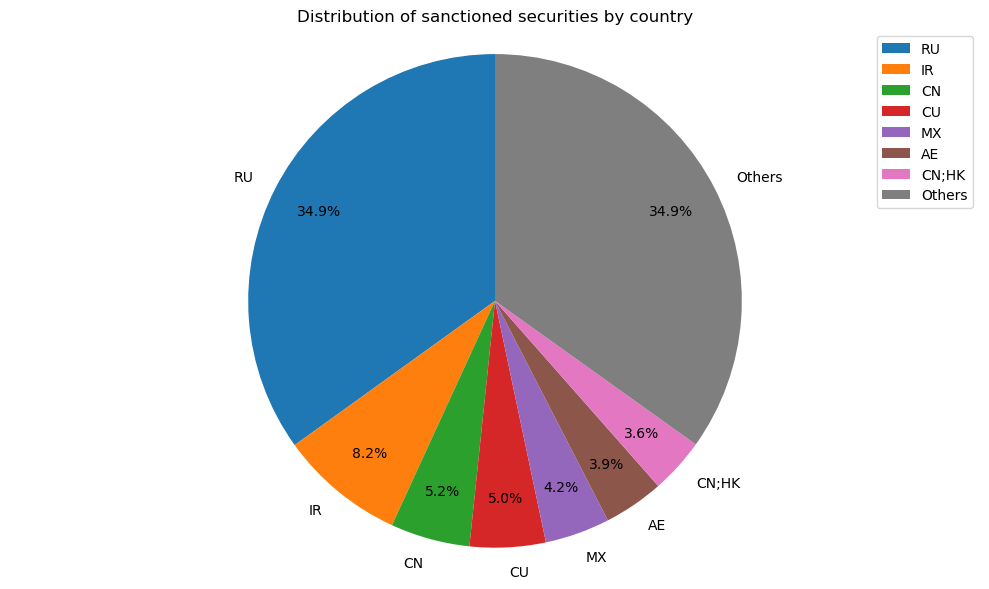

In [20]:
country_counts = df_securities['countries'].value_counts()

country_percentage = country_counts / country_counts.sum()

main_countries = country_counts[country_percentage >= 0.02]
other_countries = country_counts[country_percentage < 0.02].sum()

plot_data = main_countries.copy()
if other_countries > 0:
    plot_data['Others'] = other_countries

fig = plt.figure(figsize=(10, 6))
plot_data.plot(
    kind='pie',
    autopct='%1.1f%%', # autopct to show percentage on the pie chart
    startangle=90,
    pctdistance=0.8
)

plt.title('Distribution of sanctioned securities by country')
plt.axis('equal')
plt.tight_layout()
plt.legend()
plt.show()

## Part II: Data Analysis and Modeling
---

In [21]:
# The analytical layer is structured around three techniques: a **market-basket model** using the A-Priori algorithm to surface frequent co-occurrence patterns in entity attributes; a **recommendation system** based on UV decomposition via SGD to detect cross-list coverage gaps; and a basic **machine learning classifier** to assess whether a PEP profile is consistent with sanctions designation. Findings are exposed through an interactive Quarto dashboard rendering the main notebook.

| # | Question | Use Case | Technology  | Inputs |
| --- | -------- | --------------------- | -------| ------ |
| RQ1 | Which maritime vessels are potentially linked to a sanctioned entity despite not sharing a common ID - i.e. were they renamed or re-registered to conceal ownership? | Sanctions evasion via vessel renaming | **Jaccard Similarity** on character n-grams of `name` field: compare `df_maritime['name']` against `df_consolidated['name']`; pairs above threshold are candidate links | `df_maritime`, `df_consolidated` |
| RQ2 | Is there a statistically significant association between a vessel's country of sanctioned ownership and its registered flag state — in particular, do Russian- and Iranian-linked vessels disproportionately reflag to conduit jurisdictions? | Maritime sanctions evasion; dark fleet detection | Frequent Itemsets (A-Priori): baskets = vessels; items = {country:XX, flag:YY}; derive rule {country:RU} → {flag:PA} and compute confidence and lift against the baseline flag distribution; conduit_jurisdictions variable is the starting point | `df_maritime`, `conduit_jurisdictions` |
| RQ3 | Given an entity's current dataset memberships, which additional sanctions programmes is their profile most consistent with — i.e., which programmes have they not yet been listed in but should be? | Cross-list gap detection; targeted investigation | Recommendation System: build a binary entity × dataset utility matrix from datasets column; apply UV decomposition (SGD) to compute latent risk factors; score unobserved (entity, programme) pairs | `df_consolidated`, `df_peps_work` |
| RQ4 | Which non-sanctioned PEPs are most similar — by attribute profile — to the entities in `df_sanctioned_people_peps`, and should therefore be prioritised for enhanced due diligence? | AML/KYC prioritisation | Recommendation System (user-user collaborative filtering): Jaccard similarity on attribute sets between PEP-only entities and sanctioned PEPs; rank PEP-only entities by their average similarity to their nearest sanctioned neighbours | `df_peps_work`, `df_sanctioned_people_peps` |

### RQ1: Which maritime vessels are potentially linked to a sanctioned entity despite not sharing a common ID, i.e. were they renamed or re-registered to conceal ownership?

We use Jaccard Similarity to measure lexical similarity on name strings (detecting renamed vessels)

**Jaccard Similarity** on character n-grams of `name` field: compare `df_maritime['name']` against `df_consolidated['name']`; pairs above threshold are candidate links

`df_maritime`, `df_consolidated`

In [22]:
# Build n-gram sets
def ngrams(s, n=3):
    s = s.lower().strip()
    return set(s[i:i+n] for i in range(len(s) - n + 1))

vessel_names  = df_maritime[['id','caption']].dropna()
entity_names  = df_consolidated[['id','name']].dropna()

vessel_names['ngrams'] = vessel_names['caption'].apply(ngrams)
entity_names['ngrams'] = entity_names['name'].apply(ngrams)

In [23]:
lsh = MinHashLSH(threshold=0.5, num_perm=64) # MinHashLSH is used to find similar items based on their MinHash signatures. The threshold parameter determines the similarity threshold for considering two items as similar. In this case, a threshold of 0.5 means that two items must have at least 50% similarity in their MinHash signatures to be considered similar.

entity_hashes = {}
for _, row in entity_names.iterrows():
    m = MinHash(num_perm=64)
    for g in row['ngrams']: m.update(g.encode())
    lsh.insert(row['id'], m)
    entity_hashes[row['id']] = m

candidates = []
for _, row in vessel_names.iterrows():
    m = MinHash(num_perm=64)
    for g in row['ngrams']: m.update(g.encode())
    matches = lsh.query(m)
    for match_id in matches:
        candidates.append({'vessel_id': row['id'], 'vessel_name': row['caption'],
                           'entity_id': match_id})

In [24]:
entity_ngram_map = entity_names.set_index('id')['ngrams'].to_dict() # .set_index('id') sets the 'id' column as the index of the DataFrame, and ['ngrams'] selects the 'ngrams' column. 

# The .to_dict() method converts the selected column into a dictionary where the keys are the index values (entity IDs) and the values are the corresponding n-gram sets. This allows for quick lookup of n-grams for any given entity ID.

results = []
for c in candidates:
    A = entity_ngram_map.get(c['entity_id'], set())
    B = vessel_names.loc[vessel_names['id'] == c['vessel_id'], 'ngrams'].values
    if len(B) == 0: continue
    B = B[0]
    jaccard = len(A & B) / len(A | B) if A | B else 0
    if jaccard >= 0.5:
        results.append({**c, 'entity_name': entity_names.loc[entity_names['id']==c['entity_id'],'name'].values[0],
                        'jaccard': round(jaccard, 3)})

df_rq1 = pd.DataFrame(results).sort_values('jaccard', ascending=False)
df_rq1

# The 0.5 threshold is intentionally loose — vessel names after renaming rarely share more than half their trigrams. Review the output and raise it if there is too much noise.

# A jaccard of 1 indicates that the vessel name and entity name are identical in terms of their trigrams, while a jaccard of 0.5 indicates that they share half of their trigrams. The higher the jaccard value, the more similar the two names are.

,vessel_id,vessel_name,entity_id,entity_name,jaccard
30798,un-1718-df3b71b3d5efc70cb629e535ebb5d5408334741b,Mi Rim 2,NK-WRA7DTjp9Cb8Y45h7aJn8u,Mi Rim 2,1.0
30800,un-1718-e1c688512d37258653c962df67eb5c4cba3318a9,Ra Nam 3,NK-djhNYTBcCbnA7xwM6Xd5Se,Ra Nam 3,1.0
30801,un-1718-e66b680b23b3cf8d1c55b2b89d17bd3d7c29d908,Blue Nouvelle,NK-W96jThAdx5ddxWT5KfnkUg,Blue Nouvelle,1.0
30802,un-1718-f5497098e27ed23a030914ff03aeca751258034f,CHON MYONG 1,NK-ZWWcQbDKhHMuSE2LyYNvz7,Chon Myong 1,1.0
30803,un-1718-f63806bb0ad4c75d3347907c5684a669fc4f636e,DONG FENG 6,NK-5W3TkdPYPNiGfhzMWR9YSa,Dong Feng 6,1.0
...,...,...,...,...,...
74,bs-mou-06ba95c20cf7ff8d2814869bce2e8166f97ab691,SEA BREEZE 1,NK-dZqdxJ8PP9298bVCGqzFZL,Dubai Sea Breeze,0.5
69,bs-mou-05919372f1a070e01dc2baab6fdc2f0cbc35d5df,MARIA S,NK-Wo3zmUcz36F9c3xvvEc9HA,MARIA III,0.5
98,bs-mou-1d48d9f36fdcbca229dab0704b9145604aa8a261,UNITED S,NK-fSKHNeLR9dCBuYTurYykRG,UNITE,0.5
95,bs-mou-1918a815f157d95d0ce21fe3f963da9eb9664481,VALENTINA,NK-mFiTs28qndkRVV7SSNS2W8,VALENTE,0.5


### RQ2: Is there a statistically significant association between a vessel's country of sanctioned ownership and its registered flag state, in particular, do Russian- and Iranian-linked vessels disproportionately reflag to conduit jurisdictions?

A-Priori on `{country:XX, flag:YY}` baskets.

In [25]:
conduit_jurisdictions = ['PA', 'VU', 'MT', 'KM', 'PW', 'TV']

# Here conduit_jurisdictions is a list of country codes that are considered to be conduit jurisdictions. These are countries or territories that are often used for routing financial transactions or business activities, sometimes to take advantage of favorable tax laws or regulatory environments.


In [26]:
# To perform the A-Priori algorithm, we need to create a "basket" of items for each row in the maritime dataset. This basket will include the countries and flags associated with each vessel, as well as a flag indicating whether the vessel is registered in a conduit jurisdiction. 

def build_basket(row):
    items = []
    for c in str(row['countries']).split(';'): # for c in str(row['countries']).split(';') splits the 'countries' string into a list of individual country codes using the semicolon as a delimiter. This allows us to process each country code separately.
        if c.strip(): items.append(f"country:{c.strip()}") # c.strip removes any leading or trailing whitespace from the country code, and if the resulting string is not empty, it appends a formatted string "country:{country_code}" to the items list. This ensures that only valid country codes are included in the basket.
    if pd.notna(row['flag']): # pd.notna(row['flag']) checks if the 'flag' value is not NaN (i.e., it has a valid value). If the flag is present, it appends a formatted string "flag:{flag_code}" to the items list. Additionally, it checks if the flag is in the conduit_jurisdictions list and appends "conduit:True" to indicate that the vessel is registered in a conduit jurisdiction.
        items.append(f"flag:{row['flag'].strip()}") # appends a formatted string "flag:{flag_code}" to the items list, where {flag_code} is the cleaned-up flag value from the row. This ensures that the flag information is included in the basket for each vessel.
        if row['flag'].strip() in conduit_jurisdictions: 
            items.append("conduit:True")
    return list(set(items))

df_maritime['basket'] = df_maritime.apply(build_basket, axis=1)

In [27]:
# A Transaction Encoder is used to convert the list of items in each basket into a one-hot encoded format, which is suitable for the A-Priori algorithm. Each unique item in the baskets will become a column in the resulting DataFrame, with binary values indicating the presence or absence of that item in each basket.

te = TransactionEncoder() 
te_array = te.fit_transform(df_maritime['basket'].tolist())
basket_df = pd.DataFrame(te_array, columns=te.columns_)

freq_items = apriori(basket_df, min_support=0.03, use_colnames=True, max_len=3)

# Support at 3% on the maritime dataset should produce a non-trivial rule set — adjust down to 1% if it returns nothing.

In [28]:
rules = association_rules(freq_items, metric='confidence', min_threshold=0.4)
rules = rules[rules['lift'] > 1.2].sort_values('lift', ascending=False)

In [29]:
# Focus on rules that conclude in a conduit flag
flag_rules = rules[rules['consequents'].apply(lambda x: any('flag:' in i or 'conduit:' in i for i in x))]
flag_rules[['antecedents','consequents','support','confidence','lift']]

,antecedents,consequents,support,confidence,lift
6,frozenset({country:MH}),frozenset({flag:MH}),0.032392,0.451327,13.933226
4,frozenset({country:LR}),frozenset({flag:LR}),0.055373,0.599750,10.831144
11,frozenset({country:RU}),frozenset({flag:RU}),0.061378,0.521590,8.498037
14,"frozenset({conduit:True, country:PA})",frozenset({flag:PA}),0.152665,0.995482,6.520708
15,frozenset({flag:PA}),"frozenset({conduit:True, country:PA})",0.152665,1.000000,6.520708
17,frozenset({country:PA}),"frozenset({flag:PA, conduit:True})",0.152665,0.800969,5.246592
9,frozenset({country:PA}),frozenset({flag:PA}),0.152665,0.800969,5.246592
3,frozenset({conduit:True}),frozenset({flag:PA}),0.152665,0.784803,5.140695
2,frozenset({flag:PA}),frozenset({conduit:True}),0.152665,1.000000,5.140695
13,"frozenset({flag:PA, country:PA})",frozenset({conduit:True}),0.152665,1.000000,5.140695


The `conduit:True` item allows to isolate rules of the form `{country:RU} → {conduit:True}` directly, without having to enumerate each individual flag state.

### RQ3: Given an entity's current dataset memberships, which additional sanctions programmes is their profile most consistent with i.e., which programmes have they not yet been listed in but should be?

Binary entity × dataset matrix, factorised to find missing listings.

In [30]:
print(df_consolidated.columns.tolist())

['id', 'schema', 'name', 'aliases', 'birth_date', 'countries', 'addresses', 'identifiers', 'sanctions', 'program_ids', 'dataset', 'first_seen', 'last_seen', 'last_change']


In [31]:
# Parse the 'datasets' column (semicolon-separated)
df_consolidated['dataset_list'] = df_consolidated['dataset'].str.split(';').apply(
    lambda x: [d.strip() for d in x] if isinstance(x, list) else []
)

all_datasets = sorted({d for lst in df_consolidated['dataset_list'] for d in lst})
entity_ids   = df_consolidated['id'].tolist()

dataset_idx  = {d: i for i, d in enumerate(all_datasets)}
entity_idx   = {e: i for i, e in enumerate(entity_ids)}

M = np.zeros((len(entity_ids), len(all_datasets)), dtype=np.float32)
for _, row in df_consolidated.iterrows():
    i = entity_idx[row['id']]
    for d in row['dataset_list']:
        if d in dataset_idx:
            M[i, dataset_idx[d]] = 1.0

In [32]:
np.random.seed(42)
k   = 10   # latent dimensions — keep small for speed
eta = 0.01
lam = 0.02

U = np.random.normal(0, 0.1, (len(entity_ids), k)).astype(np.float32)
V = np.random.normal(0, 0.1, (k, len(all_datasets))).astype(np.float32)

rows, cols = np.nonzero(M)
for epoch in range(5):
    perm = np.random.permutation(len(rows))
    for p in perm:
        i, j  = rows[p], cols[p]
        e     = M[i,j] - U[i] @ V[:,j]
        U[i] += eta * (e * V[:,j] - lam * U[i])
        V[:,j]+= eta * (e * U[i]  - lam * V[:,j])
    print(f"Epoch {epoch+1} done")
    
# Epoch is a single pass through the entire dataset during the training process. In this context, it refers to one complete iteration of updating the latent feature matrices U and V based on the observed entries in the matrix M. Each epoch allows the model to learn and adjust its parameters to better approximate the underlying patterns in the data. 

Epoch 1 done
Epoch 2 done
Epoch 3 done
Epoch 4 done
Epoch 5 done


In [58]:
scores = U @ V   # predicted relevance for every (entity, dataset) pair

# Mask already-known entries so we only look at gaps
scores[M == 1] = -np.inf

# Top-5 missing dataset recommendations per entity (sample: first 20 entities)
for i in range(20):
    top_datasets = np.argsort(scores[i])[::-1][:5]
    entity_name  = df_consolidated.iloc[i]['name']
    recs         = [all_datasets[j] for j in top_datasets]
    print(f"{entity_name}: {recs}")
    
# recs is a list of the top 5 recommended datasets for the entity at index i in the df_consolidated DataFrame. The recommendations are based on the predicted relevance scores calculated from the matrix factorization model (U @ V). The higher the score, the more relevant the dataset is considered for that entity.

Myanmar Yatai International Holding Group Co., LTD.: ['Taiwan Strategic High-Tech Commodities Entity List', 'Moldovan Sanctions for Terrorism and Proliferation of WMD', 'South Africa Targeted Financial Sanctions', 'EU Sanctions Map', 'EU Council Official Journal Sanctioned Entities']
Товариство з обмеженою відповідальністю "Зелінський Групп": ['Russia Personal Sanctions Targeting US Citizens', 'Kyrgyz National List', 'EU ESMA Suspensions and Removals', 'Georgian Otkhozoria–Tatunashvili List', 'US Department of State Terrorist Exclusion']
OJSC EHMZ named after N. D. Zelinsky: ['US OFAC Specially Designated Nationals (SDN) List', 'US Trade Consolidated Screening List (CSL)', 'Taiwan Strategic High-Tech Commodities Entity List', 'Canadian Consolidated Autonomous Sanctions List', 'New Zealand Russia Sanctions']
Приватне підприємство "Магістар-СГ": ['US OFAC Specially Designated Nationals (SDN) List', 'US Trade Consolidated Screening List (CSL)', 'Taiwan Strategic High-Tech Commodities Enti

### RQ4: Which non-sanctioned PEPs are most similar, by attribute profile, to the entities in df_sanctioned_people_peps, and should therefore be prioritised for enhanced due diligence?

Jaccard on attribute sets to rank unsanctioned PEPs by similarity to sanctioned ones.

In [34]:
def attr_set_peps(row):
    # For df_peps_work (no suffix)
    countries = {f"c:{x.strip()}" for x in str(row.get('countries', '')).split(';') if x.strip()}
    return countries

def attr_set_sanctioned(row):
    # For df_sanctioned_people_peps (suffixed from merge)
    countries = {f"c:{x.strip()}" for x in str(row.get('countries_peps', '')).split(';') if x.strip()}
    return countries

sanctioned_sets = df_sanctioned_people_peps.apply(attr_set_sanctioned, axis=1).tolist()

non_sanctioned = df_peps_work[~df_peps_work['id'].isin(df_sanctioned_people_peps['id'])].copy()
non_sanctioned['attr_set'] = non_sanctioned.apply(attr_set_peps, axis=1)

# Sanity check — these must not be empty
print(sanctioned_sets[:3])
print(non_sanctioned['attr_set'].head(3))

[{'c:VE'}, {'c:VE'}, {'c:XK'}]
196776    {c:FR, c:CA}
49049           {c:CH}
131745    {c:CN, c:HK}
Name: attr_set, dtype: object


In [35]:
def jaccard(a, b):
    return len(a & b) / len(a | b) if a | b else 0.0

# Mean Jaccard to the nearest 50 sanctioned PEPs (sample for speed)
sample_sanctioned = sanctioned_sets[:50]

non_sanctioned['risk_score'] = non_sanctioned['attr_set'].apply(
    lambda s: np.mean([jaccard(s, ref) for ref in sample_sanctioned]).round(2)
)

# The sample of 50 sanctioned PEPs is a speed concession — computing against all 3,000+ sanctioned PEPs would be slow without vectorisation. If the results look thin, increase the sample. You can also replace the mean with the max similarity to favour PEPs that are very close to at least one sanctioned entity, rather than broadly similar to many.

In [36]:
non_sanctioned.sort_values('risk_score', ascending=False)[['name','countries','risk_score']]

,name,countries,risk_score
287420,"Ермакова, Эльвира Леонидовна",RU,0.24
287419,"Иванова, Светлана Васильевна",RU,0.24
287418,Olga Noskova,RU,0.24
287415,Olga Uvarova,RU,0.24
101858,Alexander Galushka,RU,0.24
...,...,...,...
536331,M. Marc Stievenard,NaN,0.00
536332,M. Maxime Parent,NaN,0.00
536333,Mme Sara Jouanneau,NaN,0.00
536342,Mme Juliette Devedeux,NaN,0.00


## Part III: Machine Learning and Predictive Modeling
---

Can we predict whether a PEP will also appear in the consolidated sanctions list using only the features available in their PEP profile (country count, alias count, identifier count, dataset count, top-country indicators)?

How much better does a high-dimensional SGD classifier perform over LDA/QDA when one-hot country features are added, and what does the gap reveal about the linearity assumption?

**Task:** binary classification — predict whether a PEP will also appear in the consolidated sanctions list.
- Label `1`: PEP ID is in `df_sanctioned_people_peps`
- Label `0`: PEP ID is in `df_peps_work` but not in `df_sanctioned_people_peps`

One paragraph. State the task, the label definition, and the three models in order of complexity: LDA (linear boundary, equal covariance) → QDA (quadratic boundary, per-class covariance) → SGD (high-dimensional, sparse one-hot features). Note that ML is exploratory here, not the primary contribution.


In [37]:
df_part3 = df_peps_work.copy()

# Simple numeric features
df_part3['n_countries']   = df_peps_work['countries'].fillna('').str.split(';').apply(lambda x: len([i for i in x if i.strip()]))
df_part3['n_aliases']     = df_peps_work['aliases'].fillna('').str.split(';').apply(lambda x: len([i for i in x if i.strip()]))
df_part3['n_identifiers'] = df_peps_work['identifiers'].fillna('').str.split(';').apply(lambda x: len([i for i in x if i.strip()]))
df_part3['has_birthdate'] = df_peps_work['birth_date'].notna().astype(int)
df_part3['n_programs']    = df_peps_work['program_ids'].fillna('').str.split(';').apply(lambda x: len([i for i in x if i.strip()]))

In [38]:
# Label
df_part3['label'] = df_part3['id'].isin(df_sanctioned_people_peps['id']).astype(int)

print(df_part3['label'].value_counts())

FEATURES_SIMPLE = ['n_countries', 'n_aliases', 'n_identifiers', 'has_birthdate', 'n_programs']
X_simple = df_part3[FEATURES_SIMPLE].fillna(0).values
y        = df_part3['label'].values

label
0    709486
1      3343
Name: count, dtype: int64


In [39]:
# Check the class distribution before moving on. If the positive class is below 10% you have an imbalance problem — `class_weight='balanced'` fixes it for SGD, and `priors` for LDA/QDA.

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, stratify=y, random_state=42
)

# `stratify=y` is not optional here — without it, a skewed split will produce a test set with almost no positives and inflated accuracy.

In [45]:
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)
y_pred_lda = lda.predict(X_test)

print("LDA")
print(metrics.classification_report(y_test, y_pred_lda))

LDA
              precision    recall  f1-score   support

           0       1.00      0.99      1.00    141897
           1       0.06      0.07      0.07       669

    accuracy                           0.99    142566
   macro avg       0.53      0.53      0.53    142566
weighted avg       0.99      0.99      0.99    142566



In [54]:
qda = QuadraticDiscriminantAnalysis(reg_param=0.9) # # QDA may throw a `LinAlgError` or `collinearity` warning if features are nearly constant within a class — which is likely given that most PEPs have `n_programs = 0`. Add `reg_param=0.1` to the constructor if it fails.
qda.fit(X_train, y_train)
y_pred_qda = qda.predict(X_test)

print("QDA")
print(metrics.classification_report(y_test, y_pred_qda))

QDA
              precision    recall  f1-score   support

           0       1.00      0.99      0.99    141897
           1       0.04      0.12      0.06       669

    accuracy                           0.98    142566
   macro avg       0.52      0.55      0.53    142566
weighted avg       0.99      0.98      0.99    142566



In [53]:
from sklearn.preprocessing import OneHotEncoder
from scipy.sparse import hstack, csr_matrix

# One-hot encode top 30 countries
top_countries = (
    df_part3['countries'].fillna('').str.split(';').explode().str.strip()
    .value_counts().head(30).index.tolist()
)

def country_onehot(countries_str):
    present = set(countries_str.split(';'))
    return [1 if c in present else 0 for c in top_countries]

X_countries = np.array(df_part3['countries'].fillna('').apply(country_onehot).tolist())
X_sgd = np.hstack([X_simple, X_countries])

X_tr_s, X_te_s, y_tr_s, y_te_s = train_test_split(
    X_sgd, y, test_size=0.2, stratify=y, random_state=42
)

sgd = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SGDClassifier(loss='modified_huber', class_weight='balanced',
                          max_iter=100, random_state=42))
])
sgd.fit(X_tr_s, y_tr_s)

print("SGD")
print(metrics.classification_report(y_te_s, sgd.predict(X_te_s)))
print(f"AUC: {roc_auc_score(y_te_s, sgd.predict_proba(X_te_s)[:,1]):.3f}")

SGD
              precision    recall  f1-score   support

           0       1.00      0.81      0.90    141897
           1       0.02      0.95      0.05       669

    accuracy                           0.82    142566
   macro avg       0.51      0.88      0.47    142566
weighted avg       1.00      0.82      0.89    142566

AUC: 0.870


In [55]:
results = pd.DataFrame([
    {'Model': 'LDA',  'Features': 'simple (5)',       'AUC': roc_auc_score(y_test, lda.predict_proba(X_test)[:,1])},
    {'Model': 'QDA',  'Features': 'simple (5)',       'AUC': roc_auc_score(y_test, qda.predict_proba(X_test)[:,1])},
    {'Model': 'SGD',  'Features': 'simple + one-hot (35)', 'AUC': roc_auc_score(y_te_s, sgd.predict_proba(X_te_s)[:,1])},
]).round(3)
results

,Model,Features,AUC
0,LDA,simple (5),0.843
1,QDA,simple (5),0.843
2,SGD,simple + one-hot (35),0.870


In [ ]:
# **The comparison is confounded.** LDA/QDA use 5 features; SGD uses 35. If SGD outperforms, you cannot tell whether that is because of the model or because of the additional features. If you want a clean comparison, also run SGD on the 5 simple features. One extra fit call.

# **LDA's Gaussian assumption is violated.** Count features like `n_aliases` and `n_programs` are zero-inflated and right-skewed — the opposite of normally distributed. LDA will still run and produce a result, but the theoretical guarantees do not hold. Acknowledge this in the methodology markdown as a known limitation, not something to fix — it is acceptable scope given ML is not the course focus.

## Conclusions
---